# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [18]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [19]:
df = pd.read_csv("/content/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [20]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [21]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [22]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

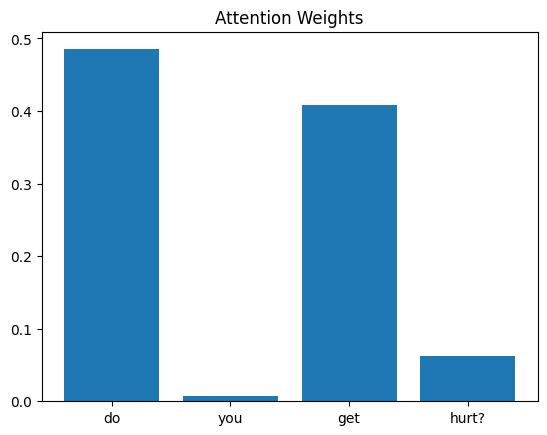

In [23]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question: do you ever breathe
Highest-attention word: do
Attention weight: 0.6996


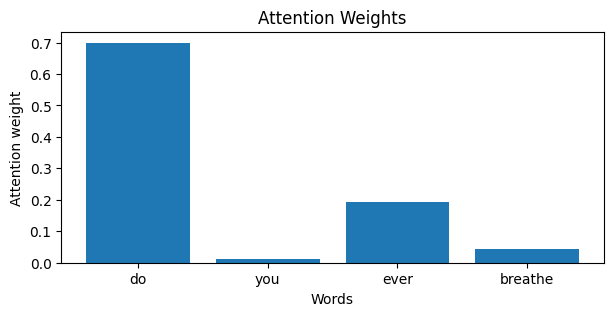

Question: can you throw up?
Highest-attention word: up
Attention weight: 0.3531


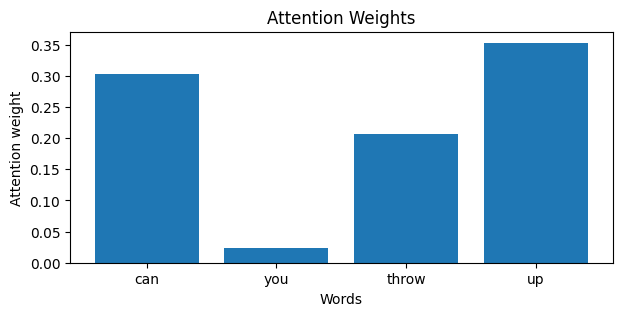

Question: can you crawl?
Highest-attention word: crawl
Attention weight: 0.5432


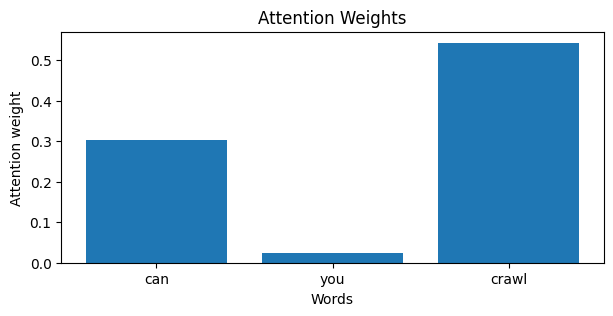

In [24]:
# Select three questions by their row positions
question_indices = [2, 4, 6]

model.eval()

for i in question_indices:
    question = df["question"].iloc[i]
    token_ids = tokenizer.texts_to_sequences([question])[0]
    words = [tokenizer.index_word[token] for token in token_ids]

    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    word_weights = weights[0, :len(words)].tolist()

    # Identify the word with the highest attention weight
    highest_index = max(
        range(len(word_weights)),
        key=lambda j: word_weights[j]
    )

    print("Question:", question)
    print("Highest-attention word:", words[highest_index])
    print(f"Attention weight: {word_weights[highest_index]:.4f}")

    # Plot attention weights
    plt.figure(figsize=(7, 3))
    plt.bar(words, word_weights)
    plt.title("Attention Weights")
    plt.xlabel("Words")
    plt.ylabel("Attention weight")
    plt.show()


**Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations**





- The highest-attention words were:
  - "do" achived (0.6996)
  - "up" achived(0.3531)
  - "crawl" achived (0.5432)
  
 "crawl" identifies the action,"up" contributes to the meaning of "throw up", "do" received the highest attention, although "breathe" is more informative about the meaning.
 Therefore, attention weights do not always reflect importance of words and controbution.






Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

![image.png](
  
)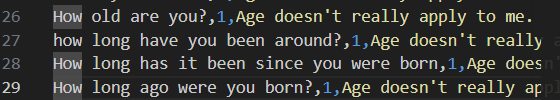

Question: how long has it been since you were born
Highest-attention word: been
Attention weight: 0.5349


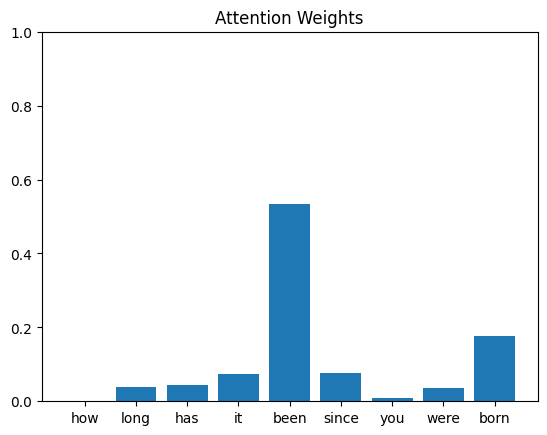

Question: how long ago were you born?
Highest-attention word: born?
Attention weight: 0.5088


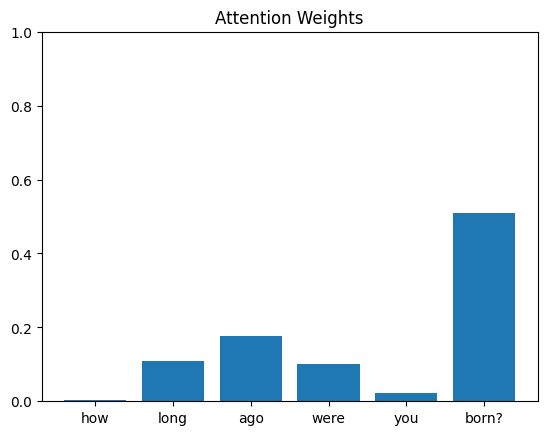

In [25]:
#26: “How long has it been since you were born?”
#27: “How long ago were you born?”

for i in [26, 27]:
    question = df["question"].iloc[i]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    word_weights = weights[0, :len(words)]
    highest_index = word_weights.argmax().item()

    print("Question:", question)
    print("Highest-attention word:", words[highest_index])
    print("Attention weight:", round(word_weights[highest_index].item(), 4))

    plt.bar(words, word_weights.tolist())
    plt.title("Attention Weights")
    plt.ylim(0, 1)
    plt.show()

**Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?**


The model focused on different words
- The highest-attention words were:
  - "been" achived (0.5349)
  - "born" achived (0.5088)

"born" identifies the event in the question, and "been" controbute the meaning of the phrase "has it been since".

both questions are asking about age but with differente expression. this affected the model attention distribution even when both questions have the same meaning.

This suggests that attention depends on how the words are used in each question rather than the meaning.